# GLACE — exploration 
This code is to explore the potential of the model GLAC.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from types import SimpleNamespace
from glace.main import build_params
from glace.core import run_simulation
from glace.figures import plot_profiles, plot_snapshots, plot_attribution, plot_data_vs_model
print('✓ imports OK')

✓ imports OK


## Paramètres
Change ce que tu veux ici, puis Shift+Entrée sur toutes les cellules suivantes.

In [2]:
# ── Physique du gaz ───────────────────────────────────────────────────────────
P_diss  = 5e6        # pression de dissociation des clathrates   [Pa]
S_Ar    = 10e-9      # solubilité Ar dans le réseau              [mol m⁻³ Pa⁻¹]

# ── Site ─────────────────────────────────────────────────────────────────────
TAC     = 4.856e-5   # total air content (données labo)          [m³_STP kg⁻¹]
b_acc   = 0.35       # taux d'accumulation                       [m yr⁻¹]
H_ice   = 1387.0     # épaisseur de glace                        [m]
p_llib  = 3          # paramètre de forme Lliboutry              [-]

# ── Transport ─────────────────────────────────────────────────────────────────
D_m2s       = 1e-11  # diffusivité dans le réseau                [m² s⁻¹]
flux_bottom = 6e-7   # flux basal Ar                             [mol m⁻² yr⁻¹]

# ── Gas loss ──────────────────────────────────────────────────────────────────
GAS_LOSS_MODE = 'none'   # 'none' ou 'data'
gas_loss_data = 1.8e-6   # taux max (mode 'data' seulement)      [yr⁻¹]
z_char        = 8.0      # hauteur caractéristique               [m]
z_gl_limit    = 20.0     # limite supérieure de la zone          [m]

# ── Grille et temps ───────────────────────────────────────────────────────────
nz = 101
Z  = 30.0            # domaine au-dessus du bed                  [m]
T  = 1e5             # durée totale de simulation                [yr]
dt = 3.0             # pas de temps                              [yr]

# ── Constantes ────────────────────────────────────────────────────────────────
rho_ice = 917.0
Vm_STP  = 22.414e-3
X_atm   = 0.934e-2   # référence atmosphérique (non utilisé pour BC/IC)

## Lancement de la simulation

In [3]:
p = SimpleNamespace(
    P_diss=P_diss, S_Ar=S_Ar, TAC=TAC, b_acc=b_acc, H_ice=H_ice, p_llib=p_llib,
    D_m2s=D_m2s, flux_bottom=flux_bottom,
    GAS_LOSS_MODE=GAS_LOSS_MODE, gas_loss_data=gas_loss_data,
    z_char=z_char, z_gl_limit=z_gl_limit,
    nz=nz, Z=Z, T=T, dt=dt,
    rho_ice=rho_ice, Vm_STP=Vm_STP, X_atm=X_atm,
)
sim = build_params(p)
result = run_simulation(sim, return_full=True)
print(f'Simulation terminée — {sim["nt"]} pas de temps')

  Umax          = -3.7851e-02 m/yr
  CFL           = 0.379  ✓
  Diffusion no. = 0.0105
  Gas loss mode   = none  (λ = 0 everywhere)
  Surface BC/IC   = 0.9658 % Ar  (topmost data point, z = 26.55 m)
Simulation terminée — 33333 pas de temps


## Figures

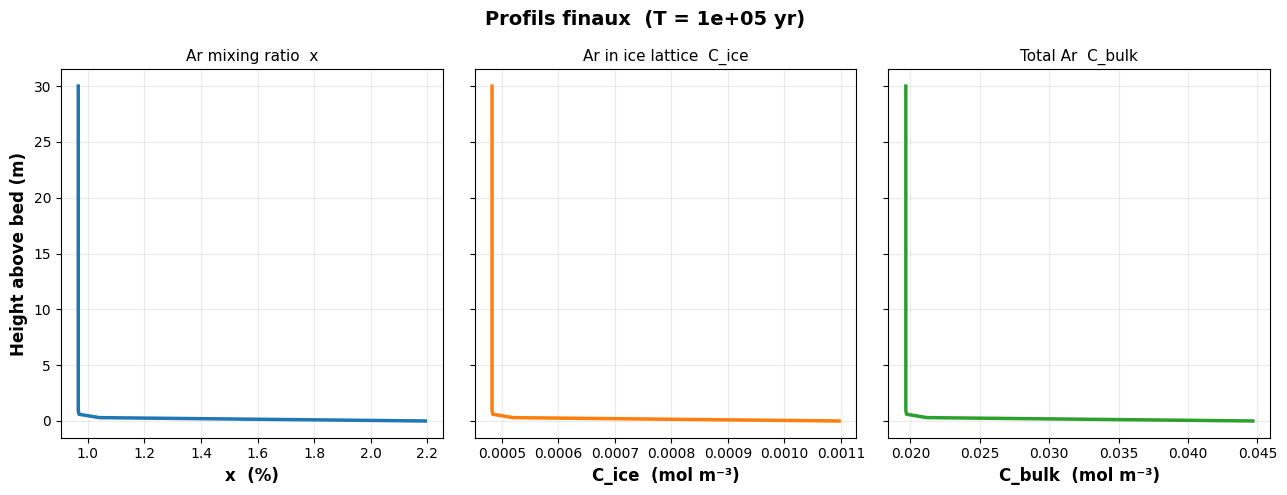

In [4]:
fig1 = plot_profiles(result, title=f'Profils finaux  (T = {T:.2g} yr)')
plt.show()

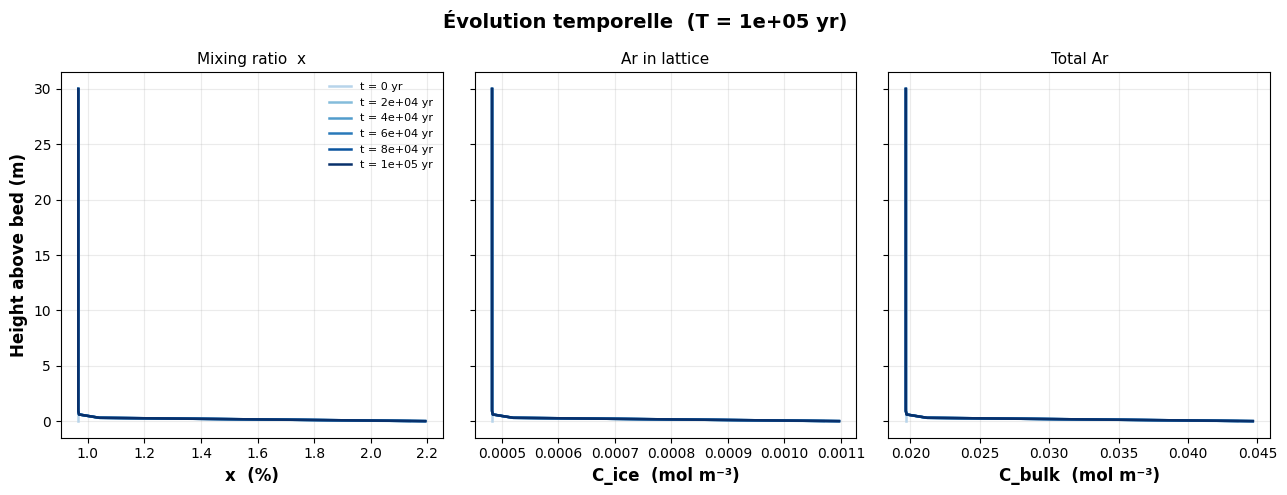

In [5]:
fig2 = plot_snapshots(result, n_snap=6, title=f'Évolution temporelle  (T = {T:.2g} yr)')
plt.show()

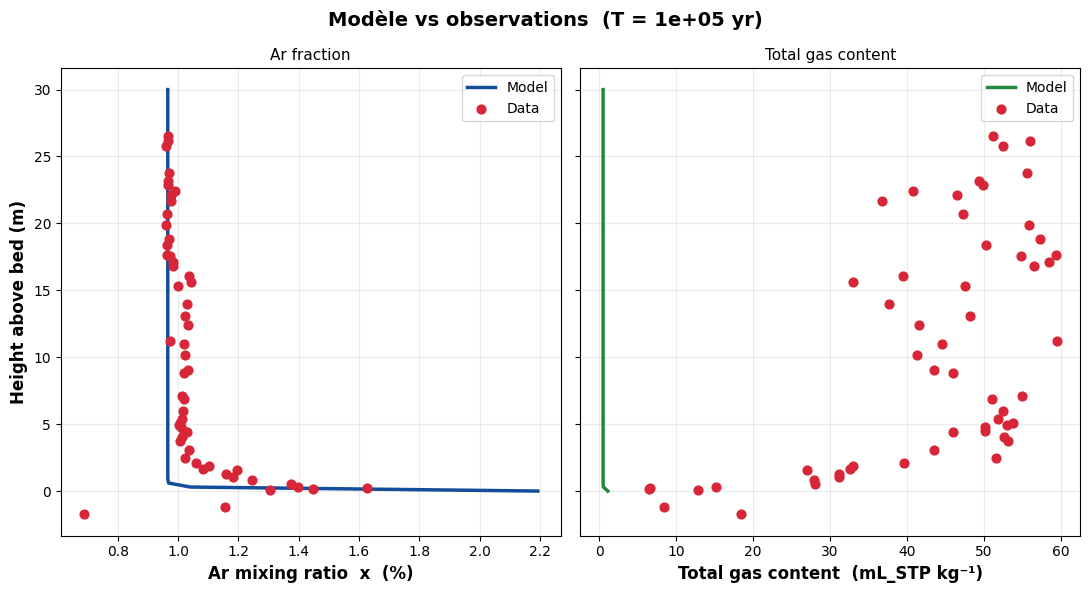

In [6]:
fig5 = plot_data_vs_model(result, title=f'Modèle vs observations  (T = {T:.2g} yr)')
plt.show()

---
## Diffusion seule — équilibre et temps caractéristique

La diffusivité effective est réduite par la fraction dissoute dans la glace :

$$D_{\text{eff}} = D \times \alpha, \quad \alpha = \frac{p_S}{p_S + n_{\text{air}}} \approx 2.46\%$$

Le temps pour atteindre l'état stationnaire par diffusion pure :

$$\tau_{\text{diff}} = \frac{Z^2}{D_{\text{eff}}} = \frac{30^2}{7.74 \times 10^{-6}} \approx \mathbf{116 \text{ Myr}}$$

**Conclusion** : à l'échelle glaciaire (~800 kyr), la diffusion seule n'atteint *jamais* l'état stationnaire.  
La figure ci-dessous compare le profil transitoire à T=1e5 yr avec la solution analytique à l'équilibre (calculée une seule fois, figure pré-enregistrée).


alpha     = 2.4550 %
D_eff     = 7.7420e-06 m²/yr
tau_diff  = 1.162e+08 yr  =  116 Myr

Figure pré-calculée (run unique, pas de recalcul) :


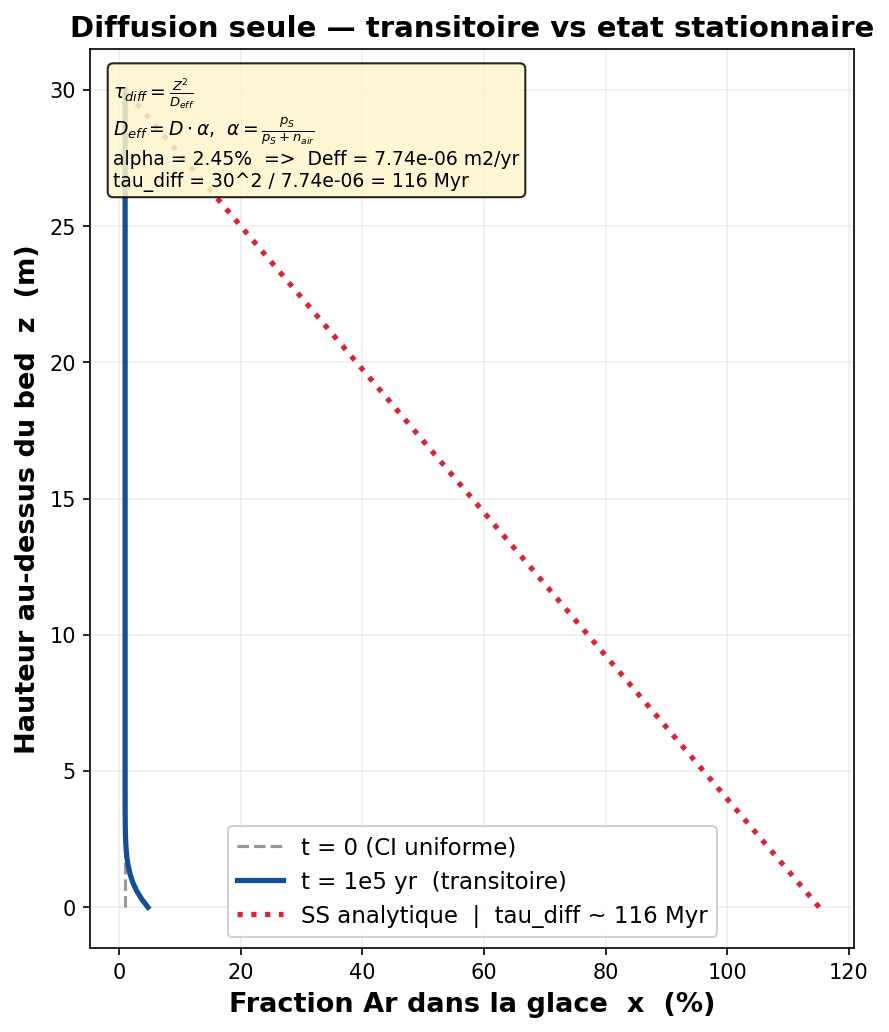

In [7]:
# ── Calcul de tau_diff (analytique, instantané) ──────────────────────────────
pS_val  = P_diss * S_Ar
n_air   = TAC * rho_ice / Vm_STP
alpha   = pS_val / (pS_val + n_air)
D_eff   = D_m2s * 3.1536e7 * alpha    # m²/yr

tau_diff = Z**2 / D_eff
print(f"alpha     = {alpha*100:.4f} %")
print(f"D_eff     = {D_eff:.4e} m²/yr")
print(f"tau_diff  = {tau_diff:.3e} yr  =  {tau_diff/1e6:.0f} Myr")
print()
print("Figure pré-calculée (run unique, pas de recalcul) :")

# Affiche la figure pré-enregistrée
from IPython.display import Image, display
display(Image(filename='figures/fig_diffusion_SS.png', width=500))


---
## Advection — temps pour atteindre le SS

Avec advection, le temps de résidence à la hauteur z est :

$$\tau_{\text{res}}(z) = \frac{H}{(p+2)\,b_{\text{acc}}} \ln\!\left(\frac{Z}{z}\right)$$

À z = 1 m : **τ_res ~ 2 700 yr**. Le SS est atteint en ~5–10 × τ_res soit **~15 000–27 000 yr**.
Figure pré-calculée (run unique T = 30 000 yr) :

In [ ]:
# Calcul analytique de tau_res
H_ice = 1387.0; p_llib = 3; b_acc = 0.35; Z = 30.0
tau_res_1m = H_ice / ((p_llib+2)*b_acc) * np.log(Z / 1.0)
print("tau_res(z=1m) = {:.0f} yr".format(tau_res_1m))
print("SS attendu    ~ {:.0f} – {:.0f} yr".format(5*tau_res_1m, 10*tau_res_1m))

from IPython.display import Image, display
display(Image(filename='figures/fig_advection_SS.png', width=450))

---
## Nombre de Péclet

$$Pe = \frac{|u_{\text{max}}| \cdot Z}{D_{\text{eff}}}$$

Quand Pe >> 1, l'advection domine complètement la diffusion.
Figure pré-calculée (5 valeurs de D, T = 1e5 yr) :

In [ ]:
# Calcul de Pe pour chaque D
pS_val  = P_diss * S_Ar
n_air   = TAC * rho_ice / Vm_STP
alpha   = pS_val / (pS_val + n_air)

H_ice = 1387.0; p_llib = 3; b_acc = 0.35; Z = 30.0
# u_max approxime (Lliboutry, z->0)
import params as _p; import numpy as np
z_arr = np.linspace(0,1,101)*Z
zeta  = z_arr/H_ice
u_max = b_acc * ((p_llib+2)*zeta - (p_llib+2)*zeta**(p_llib+1) + zeta**(p_llib+2))
u_max_val = float(np.max(np.abs(u_max)))

for D in [1e-9, 1e-10, 1e-11, 1e-12, 1e-13]:
    D_eff = D * 3.1536e7 * alpha
    Pe = u_max_val * Z / D_eff
    print("D = {:.0e} m2/s  =>  Pe = {:.2e}  ({})".format(
          D, Pe, "advection domine" if Pe > 10 else "diffusion importante"))

from IPython.display import Image, display
display(Image(filename='figures/fig_peclet.png', width=700))

---
## Gas loss — ajout et comparaison

Comparaison modèle sans vs avec gas loss (λ(z) = λ_max · exp(−z/z_char)).
Figure pré-calculée (T = 1e5 yr) :

In [ ]:
from IPython.display import Image, display
display(Image(filename='figures/fig_gasloss.png', width=600))
print("Gas loss_data = {:.2e} yr-1  |  z_char = {} m  |  z_limit = {} m".format(
      gas_loss_data, z_char, z_gl_limit))
print("Effet net max sur x : ~0.03 % (Ar noble gas, effet compense par flux basal)")

## Attribution des processus
Compare : diffusion seule → + advection → + gas loss

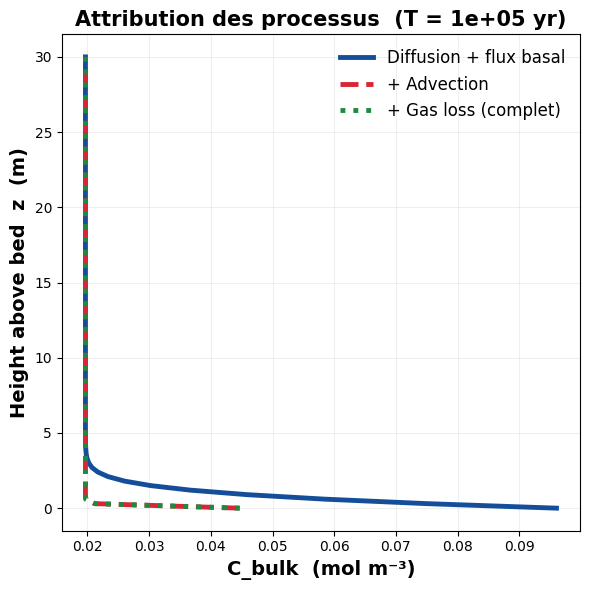

In [8]:
z = sim['z']

p1 = dict(sim); p1['u'] = np.zeros_like(sim['u']); p1['lambda_z'] = np.zeros_like(sim['lambda_z'])
p2 = dict(sim); p2['lambda_z'] = np.zeros_like(sim['lambda_z'])
p3 = dict(sim)

r1 = run_simulation(p1)
r2 = run_simulation(p2)
r3 = run_simulation(p3)

fig4 = plot_attribution(
    {'Diffusion + flux basal': r1['C_bulk'], '+ Advection': r2['C_bulk'], '+ Gas loss (complet)': r3['C_bulk']},
    z, title=f'Attribution des processus  (T = {T:.2g} yr)'
)
plt.show()